In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

In [8]:
# dataset creation
np.random.seed(42)
data= pd.DataFrame({ 'age': np.random.randint(18, 65, 100),
                    'Income': np.random.randint(30000, 100000, 100),
                    'SpendingScore': np.random.randint(1, 100, 100) })
data.head()

,age,Income,SpendingScore
0,56,32695,59
1,46,78190,36
2,32,35258,19
3,60,69504,90
4,25,63159,67


In [4]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

In [12]:
clustering= AgglomerativeClustering(n_clusters=3, linkage='ward')
data['Cluster']= clustering.fit_predict(data)
data.head()

,age,Income,SpendingScore,Cluster
0,56,32695,59,2
1,46,78190,36,0
2,32,35258,19,2
3,60,69504,90,1
4,25,63159,67,1


Text(0.5, 1.0, 'Customer Segment')

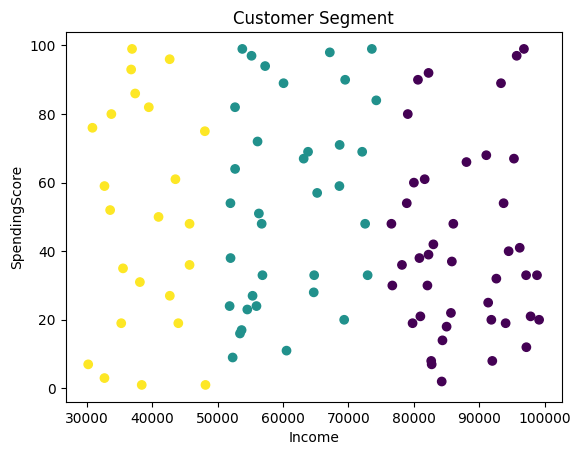

In [14]:
plt.scatter(data['Income'], data['SpendingScore'], c=data['Cluster'], cmap='viridis')
plt.xlabel('Income')
plt.ylabel('SpendingScore')
plt.title('Customer Segment') 

In [19]:
new_customer = pd.DataFrame({'Age': [30],
                             'Income': [50000],
                             'SpendingScore': [70]})
scaled_new_customer = scaler.transform(new_customer)

# Add new customer to the original scaled data
scaled_combined_data = pd.concat([pd.DataFrame(scaled_data), pd.DataFrame(scaled_new_customer)])
combined_clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
combined_clustering.fit(scaled_combined_data)

# Predict the cluster of the new customer
predicted_cluster = combined_clustering.labels_[-1]  # Get the last cluster label
print(f"The new customer's predicted cluster is {predicted_cluster}")

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- Age
Feature names seen at fit time, yet now missing:
- age


In [20]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

# Example dataset
data = pd.DataFrame({'Age': [25, 32, 40, 28, 35],
                     'Income': [40000, 50000, 60000, 45000, 52000],
                     'SpendingScore': [60, 70, 50, 80, 75]})

# Scale the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

# Fit AgglomerativeClustering
clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
clustering.fit(scaled_data)

# New customer data
new_customer = pd.DataFrame({'Age': [30],
                             'Income': [50000],
                             'SpendingScore': [70]})
scaled_new_customer = scaler.transform(new_customer)

# Add new customer to the original scaled data
scaled_combined_data = pd.concat([pd.DataFrame(scaled_data), pd.DataFrame(scaled_new_customer)])
combined_clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
combined_clustering.fit(scaled_combined_data)

# Predict the cluster of the new customer
predicted_cluster = combined_clustering.labels_[-1]  # Get the last cluster label
print(f"The new customer's predicted cluster is {predicted_cluster}")

The new customer's predicted cluster is 0
